# Low-fidelity prototype of the two dashboard screens

**Data source:** none (layout only); the dashboard uses `data/processed/hotel_bookings_clean.csv` and `country_names.csv`.
**Date:** 2026-11-05, updated 2026-11-09 for the refined dashboard
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** Clean wireframes of the main screen and the detail screen (Part 4, task 4.3). After the first build, the students decided that each screen must fit a 16:9 desktop screen in full-screen mode without scrolling, so the wireframes are drawn on a 1536 × 864 px window (a common 16:9 laptop size). Boxes show where each KPI, chart, control and text goes; the small drawings inside the chart boxes only show the chart type, not real data.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: layout grid](#4.-Analysis:-layout-grid)
5. [Accessible visualisation: wireframes](#5.-Accessible-visualisation:-wireframes)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

IMAGES_DIR = Path('../images')
OUTPUT_DIR = Path('lowfi_prototype_output')
IMAGES_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

SCREEN_W, SCREEN_H = 1536, 864          # 16:9 window, full screen, in px
INK, GREY, PALE = '#1A1A1A', '#595959', '#F2F2F2'
plt.rcParams.update({'font.family': 'DejaVu Sans'})
print('Python', sys.version.split()[0], '| matplotlib', matplotlib.__version__, '| window', SCREEN_W, 'x', SCREEN_H,
      '| ratio', round(SCREEN_W / SCREEN_H, 3))

Python 3.13.18 | matplotlib 3.11.2 | window 1536 x 864 | ratio 1.778


## 1. Data loading

No data is loaded: a low-fidelity prototype shows structure, not values (course 03, prototype techniques).

## 2. Initial exploration

The content of each screen comes from the decisions of tasks 2.3 and 4.1, revised with the students on 9 November: the main screen answers Q1, Q5 and Q7 (seasons); the detail screen answers Q2, Q3, Q4 and Q6 (source markets). The map shares a box with the country chart (a Chart / Map switch) instead of hiding behind "Show more".

## 3. Cleaning and preparation

Not applicable.

## 4. Analysis: layout grid

In [2]:
# ── Boxes of each screen, in px from the top-left corner: (x, y, width, height) ─
# Same frame on both screens (consistency, course 06): header band, KPI row, charts, filter panel on the right,
# one-line footer. Gaps of 16 px; the whole page fits 1536 x 864 without scrolling.
FRAME = {
    'header':  (0, 0, 1536, 64),
    'kpis':    (16, 76, 1216, 90),
    'filters': (1248, 76, 272, 738),
    'footer':  (16, 826, 1504, 38),
}
MAIN = {
    'chart_main':  (16, 178, 1216, 338),    # C1, focal point, full width
    'chart_left':  (16, 533, 600, 282),     # C2 calendar heatmap
    'chart_right': (632, 533, 600, 282),    # C3
}
DETAIL = {
    'chart_left':  (16, 178, 600, 332),     # C4 dumbbell, or C5 map (switch)
    'chart_right': (632, 178, 600, 332),    # C9 animated bubbles
    'chart_wide':  (16, 526, 1216, 288),    # C7 and C8 box plots side by side, one shared country axis order
}

# Share of the content area (KPIs + charts, without header, filters and footer) taken by each chart box
content_area = FRAME['kpis'][2] * (FRAME['filters'][1] + FRAME['filters'][3] - FRAME['kpis'][1])
shares = pd.DataFrame([(screen_name, part, round(100 * w * h / content_area, 1))
                       for screen_name, screen in [('main', MAIN), ('detail', DETAIL)]
                       for part, (x, y, w, h) in screen.items()], columns=['screen', 'box', '% of content area'])
bottom = max(y + h for screen in [FRAME, MAIN, DETAIL] for x, y, w, h in screen.values())
print('Lowest edge of any box:', bottom, 'px of', SCREEN_H, '-> no scrolling' if bottom <= SCREEN_H else '-> scrolls')
shares

Lowest edge of any box: 864 px of 864 -> no scrolling


,screen,box,% of content area
0,main,chart_main,45.8
1,main,chart_left,18.9
2,main,chart_right,18.9
3,detail,chart_left,22.2
4,detail,chart_right,22.2
5,detail,chart_wide,39.0


**Finding:** both screens fit the 16:9 window. On the main screen C1 is the focal point and takes 46 % of the content area, above the 40 % that the data-viz skill asks for. The detail screen has no single focal chart: its three boxes take 22 %, 22 % and 39 % (the last one holds the two box plots, which share one country order). The country chart is placed first, top left, where reading starts (Z pattern, course 06), and this deviation from the 40 % guideline is reported in Part 6.

## 5. Accessible visualisation: wireframes

In [3]:
# ── Drawing helpers ───────────────────────────────────────────────────────────

def box(ax, rect, label, fill='white', size=9, weight='normal', align='center'):
    x, y, w, h = rect
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=fill, edgecolor=INK, linewidth=1))
    if label:
        tx = x + w / 2 if align == 'center' else x + 10
        ax.text(tx, y + 10, label, ha=align, va='top', fontsize=size, color=INK, weight=weight, linespacing=1.25)


def card_buttons(ax, rect, buttons):
    """Small buttons at the top right of a chart box, e.g. [Table]."""
    x, y, w, h = rect
    right = x + w - 10
    for label in reversed(buttons):
        width = 14 + 9 * len(label)
        ax.add_patch(plt.Rectangle((right - width, y + 8), width, 26, facecolor='white', edgecolor=GREY, linewidth=0.8))
        ax.text(right - width / 2, y + 21, label, ha='center', va='center', fontsize=5, color=INK)
        right -= width + 6


def sketch_lines(ax, rect, series=('City', 'Resort')):
    """Two sketched lines (solid and dashed) with end labels: a line chart with two series."""
    x, y, w, h = rect
    t = np.linspace(0, 1, 26)
    for k, (style, label) in enumerate(zip(['-', '--'], series)):
        values = 0.55 + 0.25 * np.sin(2 * np.pi * (t - 0.15 * k)) * (1 - 0.4 * k) - 0.25 * k
        xs = x + 40 + t * (w - 110)
        ys = y + h - 30 - values * (h - 95)
        ax.plot(xs, ys, linestyle=style, color=INK, linewidth=1.2)
        ax.text(xs[-1] + 6, ys[-1], label, fontsize=6, va='center', color=INK)
    ax.plot([x + 40, x + 40], [y + 60, y + h - 25], color=GREY, linewidth=0.8)
    ax.plot([x + 40, x + w - 60], [y + h - 25, y + h - 25], color=GREY, linewidth=0.8)


def sketch_heatmap(ax, rect):
    """Calendar heatmap: 6 rows (hotel and year) x 12 months, grey classes with dots."""
    x, y, w, h = rect
    rng = np.random.default_rng(3)
    cell_w, cell_h = (w - 200) / 12, (h - 80) / 6
    for row in range(6):
        ax.text(x + 92, y + 55 + (row + 0.5) * cell_h, ['City 2015', 'City 2016', 'City 2017', 'Resort 2015',
                'Resort 2016', 'Resort 2017'][row], fontsize=4.5, ha='right', va='center', color=GREY)
        for col in range(12):
            if (row % 3 == 0 and col < 6) or (row % 3 == 2 and col > 7):
                continue                                   # months outside the data (Jan-Jun 2015, Sep-Dec 2017)
            level = rng.integers(0, 6)
            ax.add_patch(plt.Rectangle((x + 97 + col * cell_w, y + 55 + row * cell_h), cell_w - 3, cell_h - 3,
                                       facecolor=str(0.95 - 0.12 * level), edgecolor='none'))
            for dot in range(level):
                ax.plot(x + 97 + col * cell_w + (dot + 1) * cell_w / (level + 1), y + 55 + (row + 0.5) * cell_h,
                        'o', ms=0.8, color='white' if level > 3 else INK)
    ax.text(x + w - 92, y + 60, 'Legend:\n7 classes\nof % cancelled', fontsize=4.5, va='top', color=GREY)


def sketch_dumbbell(ax, rect, n=11):
    """Dumbbell: one row per country, a circle (City) and a square (Resort) joined by a line."""
    x, y, w, h = rect
    rng = np.random.default_rng(1)
    for i in range(n):
        row_y = y + 70 + i * (h - 90) / n
        ax.plot([x + 20, x + 70], [row_y, row_y], color=GREY, linewidth=2)
        a, b = sorted(rng.uniform(0.05, 1, 2) * (w - 180) * (0.85 ** i) + x + 90)
        ax.plot([a, b], [row_y, row_y], color=GREY, linewidth=0.8)
        ax.plot(a, row_y, 'o', ms=3, color=INK)
        ax.plot(b, row_y, 's', ms=3, color=INK, mfc='white')


def sketch_bubbles(ax, rect):
    """Bubbles: x days booked ahead, y % of the year arriving that month, size guests; Play and a month slider."""
    x, y, w, h = rect
    rng = np.random.default_rng(7)
    for k in range(10):
        ax.add_patch(plt.Circle((x + 70 + rng.uniform(0, w - 140), y + 80 + rng.uniform(0, h - 160)),
                                rng.uniform(6, 22), facecolor='#DDDDDD', edgecolor=GREY, linewidth=0.6))
    ax.text(x + w - 20, y + 50, 'March', fontsize=9, ha='right', va='top', color=GREY, weight='bold')
    ax.plot([x + 40, x + 40], [y + 45, y + h - 50], color=GREY, linewidth=0.8)
    ax.plot([x + 40, x + w - 20], [y + h - 50, y + h - 50], color=GREY, linewidth=0.8)
    ax.add_patch(plt.Rectangle((x + 15, y + h - 38), 60, 26, facecolor='white', edgecolor=INK, linewidth=0.8))
    ax.text(x + 45, y + h - 25, '[ Play ]', ha='center', va='center', fontsize=5, color=INK)
    ax.plot([x + 90, x + w - 90], [y + h - 25, y + h - 25], color=GREY, linewidth=1.5)
    ax.plot(x + 90 + 2 / 11 * (w - 180), y + h - 25, 'o', ms=4, color=INK)
    ax.text(x + w - 80, y + h - 25, 'Month', fontsize=5, va='center', color=INK)


def sketch_boxes(ax, rect, n=11):
    """Two box plots side by side (nights, days booked ahead), one row per country."""
    x, y, w, h = rect
    rng = np.random.default_rng(5)
    for half in range(2):
        px = x + half * w / 2
        for i in range(n):
            row_y = y + 60 + i * (h - 75) / n
            if half == 0:
                ax.plot([px + 20, px + 70], [row_y, row_y], color=GREY, linewidth=2)
            low, q1, med, q3, high = np.sort(rng.uniform(0, 1, 5)) * (w / 2 - 140) + px + 90
            ax.plot([low, high], [row_y, row_y], color=GREY, linewidth=0.6)
            ax.add_patch(plt.Rectangle((q1, row_y - 5), q3 - q1, 10, facecolor='#DDDDDD', edgecolor=GREY, linewidth=0.6))
            ax.plot([med, med], [row_y - 6, row_y + 6], color=INK, linewidth=1.5)


def draw_screen(screen, title, labels, file_name, extra=None):
    fig = plt.figure(figsize=(7.2, 7.2 * SCREEN_H / SCREEN_W + 0.35))
    ax = fig.add_axes([0.005, 0.005, 0.99, 0.99 * (7.2 * SCREEN_H / SCREEN_W) / (7.2 * SCREEN_H / SCREEN_W + 0.35)])
    ax.set_xlim(0, SCREEN_W)
    ax.set_ylim(SCREEN_H, 0)
    ax.axis('off')
    box(ax, (0, 0, SCREEN_W, SCREEN_H), None)
    box(ax, FRAME['header'], labels['header'], fill=PALE, size=6, weight='bold', align='left')
    # KPIs: four equal cards
    kx, ky, kw, kh = FRAME['kpis']
    for i, kpi in enumerate(labels['kpis']):
        box(ax, (kx + i * kw / 4 + 4, ky, kw / 4 - 8, kh), kpi, size=5.5)
    box(ax, FRAME['filters'], labels['filters'], fill=PALE, size=5.5, align='left')
    box(ax, FRAME['footer'], labels['footer'], fill=PALE, size=5, align='left')
    for key, rect in screen.items():
        box(ax, rect, labels[key], size=5.5, align='left')
        card_buttons(ax, rect, labels.get(key + '_buttons', ['Table']))
    if extra:
        extra(ax)
    fig.suptitle(title, x=0.01, y=0.985, ha='left', va='top', fontsize=10, color=INK)
    fig.savefig(IMAGES_DIR / file_name, dpi=200)
    return fig


FILTERS = ('Filters\n\nHotel:\n( ) Both  ( ) City  ( ) Resort\n\nYear of arrival:\n[ All years  v ]\n\n'
           'Showing: both hotels,\nall years\n\n[ Reset filters ]\n\n')
HEADER = ('Hotel guests in Lisbon and the Algarve - {subtitle}\n'
          '[Main screen]  [Countries of the guests]  [Accessibility help]   [Night mode]')
print('Drawing helpers ready')

Drawing helpers ready


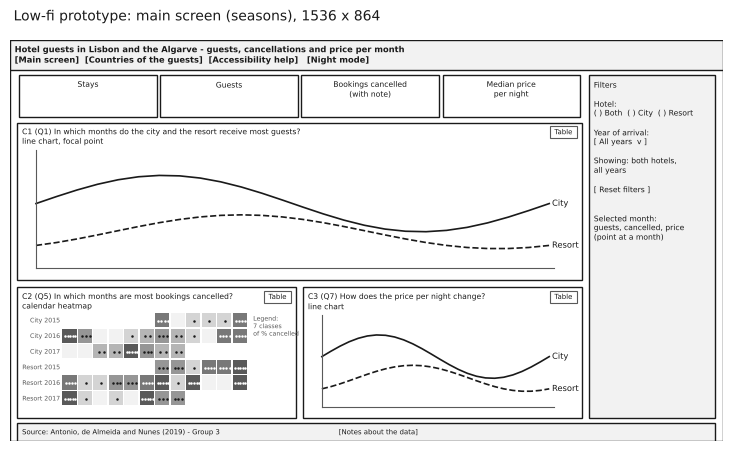

In [4]:
# ── Main screen ───────────────────────────────────────────────────────────────
main_labels = {
    'header': HEADER.format(subtitle='guests, cancellations and price per month'),
    'kpis': ['Stays', 'Guests', 'Bookings cancelled\n(with note)', 'Median price\nper night'],
    'filters': FILTERS + '\nSelected month:\nguests, cancelled, price\n(point at a month)',
    'footer': 'Source: Antonio, de Almeida and Nunes (2019) - Group 3                                                      [Notes about the data]',
    'chart_main': 'C1 (Q1) In which months do the city and the resort receive most guests?\nline chart, focal point',
    'chart_left': 'C2 (Q5) In which months are most bookings cancelled?\ncalendar heatmap',
    'chart_right': 'C3 (Q7) How does the price per night change?\nline chart',
}
def main_extra(ax):
    sketch_lines(ax, MAIN['chart_main'])
    sketch_heatmap(ax, MAIN['chart_left'])
    sketch_lines(ax, MAIN['chart_right'])

draw_screen(MAIN, 'Low-fi prototype: main screen (seasons), 1536 x 864', main_labels, 'lowfi_main_screen.png', main_extra)
plt.show()

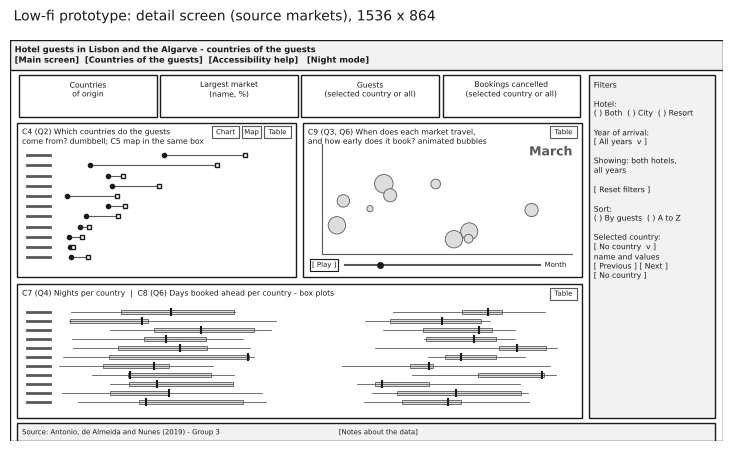

In [5]:
# ── Detail screen ─────────────────────────────────────────────────────────────
detail_labels = {
    'header': HEADER.format(subtitle='countries of the guests'),
    'kpis': ['Countries\nof origin', 'Largest market\n(name, %)', 'Guests\n(selected country or all)', 'Bookings cancelled\n(selected country or all)'],
    'filters': FILTERS + 'Sort:\n( ) By guests  ( ) A to Z\n\nSelected country:\n[ No country  v ]\nname and values\n[ Previous ] [ Next ]\n[ No country ]',
    'footer': main_labels['footer'],
    'chart_left': 'C4 (Q2) Which countries do the guests\ncome from? dumbbell; C5 map in the same box',
    'chart_left_buttons': ['Chart', 'Map', 'Table'],
    'chart_right': 'C9 (Q3, Q6) When does each market travel,\nand how early does it book? animated bubbles',
    'chart_wide': 'C7 (Q4) Nights per country  |  C8 (Q6) Days booked ahead per country - box plots',
}
def detail_extra(ax):
    sketch_dumbbell(ax, DETAIL['chart_left'])
    sketch_bubbles(ax, DETAIL['chart_right'])
    sketch_boxes(ax, DETAIL['chart_wide'])

draw_screen(DETAIL, 'Low-fi prototype: detail screen (source markets), 1536 x 864', detail_labels, 'lowfi_detail_screen.png', detail_extra)
plt.show()

## 6. Export

In [6]:
# ── Export: the layout grid, so Part 6 can compare the built page with it ────
rows = [(screen_name, part, *rect) for screen_name, screen in [('frame', FRAME), ('main', MAIN), ('detail', DETAIL)]
        for part, rect in screen.items()]
layout = pd.DataFrame(rows, columns=['screen', 'part', 'x_px', 'y_px', 'width_px', 'height_px'])
layout.to_csv(OUTPUT_DIR / 'layout_grid.csv', index=False)
layout

,screen,part,x_px,y_px,width_px,height_px
0,frame,header,0,0,1536,64
1,frame,kpis,16,76,1216,90
2,frame,filters,1248,76,272,738
3,frame,footer,16,826,1504,38
4,main,chart_main,16,178,1216,338
5,main,chart_left,16,533,600,282
6,main,chart_right,632,533,600,282
7,detail,chart_left,16,178,600,332
8,detail,chart_right,632,178,600,332
9,detail,chart_wide,16,526,1216,288


## Conclusions

1. Both screens share the same frame (header band with the night-mode button, KPI row, filter panel on the right, one-line footer with a "Notes about the data" button), so the user learns it once (consistency, course 06).
2. Each screen shows 4 KPIs and 3 chart boxes and fits a 16:9 window without scrolling. On the main screen C1 is the focal point (46 % of the content area); the detail screen has no box above 40 %.
3. The map no longer hides behind "Show more": it shares the country chart's box through a Chart / Map switch, so three charts are visible at most (cognitive accessibility).